In [265]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

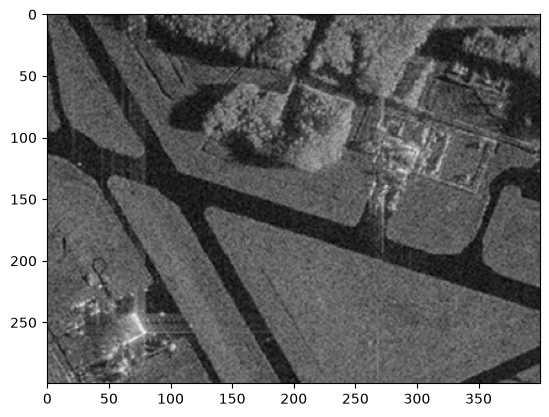

In [266]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

#1

In [267]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [268]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255

15
33
51
69
87
105
123
140
156
177
195
213
231
248
268
285
303
321
339
357
375
393
411
357
291
298
304
310
314
322
328
334
340
346
351
351
348
347
343
342
339
335
334
331
329
321
315
309
305
297
294
286
277
277
272
266
261
251
246
236
230
226
224
216
211
206
198
191
189
181
176
168
161
125
114
88
87
83
80
78
76
71
67
66
63
61
60
60
60
58
57
54
53
52
50
48
48
45
44
43
42
39
37
36
35
36
34
33
31
30
29
28
25
23
22
21
18
16
15
12
10
6
2
0


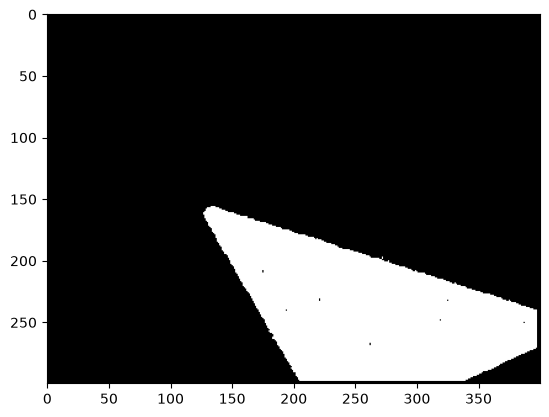

In [269]:
seed_point = (250, 250) 
mask = region_growing(image_gray, seed_point, homo_average, 2, 33)
plt.imshow(mask, cmap="gray")

#2

In [270]:
def homo_diff(img, mask, point, T):
    y, x = point
    neighbors = [(y-1, x), (y+1, x), (y, x-1), (y, x+1)]
    
    for ny, nx in neighbors:
        if 0 <= ny < img.shape[0] and 0 <= nx < img.shape[1]:
            if mask[ny, nx] > 0:
                if abs(int(img[y, x]) - int(img[ny, nx])) <= T:
                    return True
    return False

4
7
7
11
16
18
18
22
24
26
31
37
46
46
44
39
43
49
58
65
71
74
74
68
71
82
82
83
81
83
91
99
106
109
110
121
128
130
140
121
119
134
145
146
132
133
133
125
141
151
141
150
161
161
164
185
193
193
185
185
179
174
192
207
208
213
208
209
218
197
193
201
204
183
165
164
165
170
165
166
167
169
199
204
182
174
158
166
162
135
131
122
119
119
116
100
93
100
99
110
113
118
121
119
113
120
117
105
95
94
90
89
90
99
105
114
118
113
110
113
110
112
115
106
101
102
103
104
99
96
92
90
93
87
85
94
96
98
91
84
90
80
79
89
97
89
88
98
83
71
71
68
69
74
69
61
59
56
51
57
56
51
48
44
49
54
54
60
63
59
60
58
63
64
55
55
57
55
52
45
38
37
38
38
42
36
27
25
23
11
10
9
9
12
15
14
15
12
7
4
5
5
5
5
3
3
3
2
3
3
2
4
2
3
2
2
2
1
3
1
1
1
0


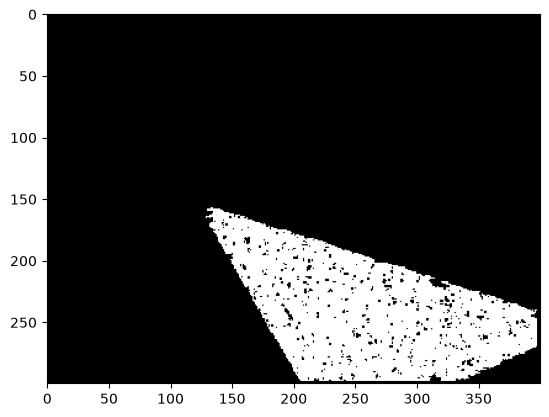

In [271]:
seed_point = (250, 250) 
mask_diff = region_growing(image_gray, seed_point, homo_diff, 2, 7)
plt.imshow(mask_diff, cmap="gray")

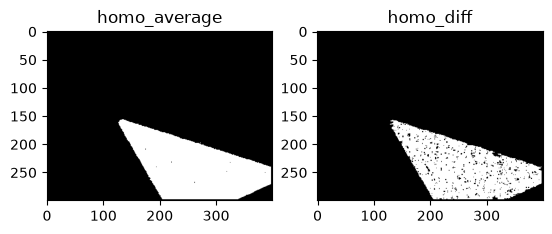

In [272]:
plt.subplot(1, 2, 1)
plt.title('homo_average')
plt.imshow(mask, cmap="gray")

plt.subplot(1, 2, 2)
plt.title('homo_diff')
plt.imshow(mask_diff, cmap="gray")

#3

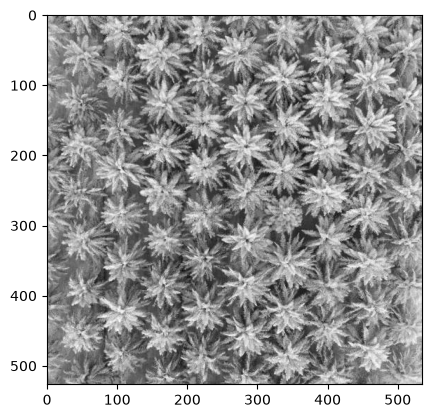

In [273]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

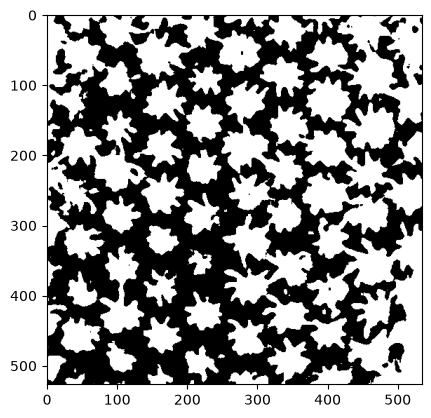

In [274]:
image_blur = cv2.medianBlur(image_gray, 9)
ret, thresh = cv2.threshold(image_blur,0,255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

In [275]:
kernel = np.ones((3,3), np.uint8)
clean = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

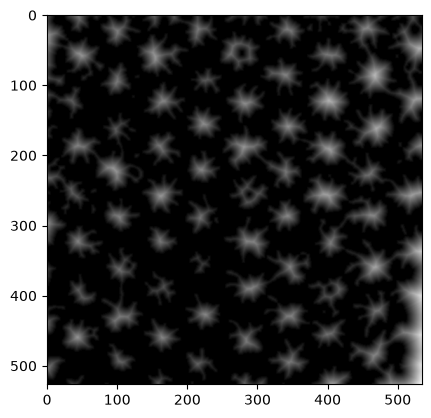

In [276]:
dist = cv2.distanceTransform(clean, cv2.DIST_L2, 5)
plt.imshow(dist, cmap="gray")

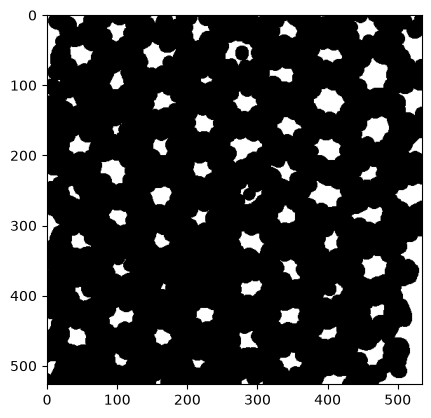

In [277]:
ret, sure_fg = cv2.threshold(dist, 0.25 * dist.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg, cmap="gray")

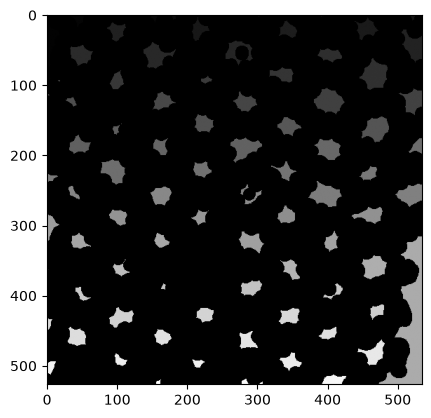

In [278]:
sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)
plt.imshow(markers, cmap="gray")

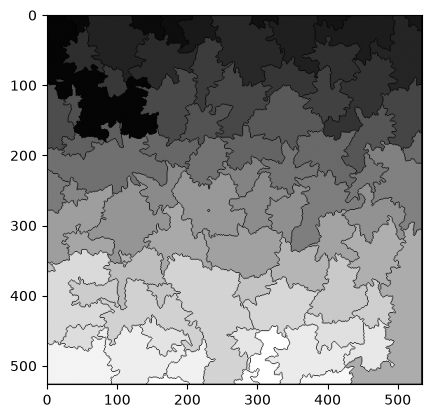

In [279]:
markers = cv2.watershed(image, markers)
plt.imshow(markers, cmap="gray")

In [280]:
print(f"Количество пальмовых деревьев: {ret-1}")

Количество пальмовых деревьев: 88
